In [1]:
import numpy as np
import matplotlib.pyplot as plt
from functools import partial

2d gaussian centered at mu, with width sigma evaluated on the unit circle. 

In [3]:
phi_mu = 0.7
sigma = 0.2

def log_gaussian_on_circle(phis, phi_mu, sigma):
    """
    ## bugs: 
    - unnormalized
    - returns an array even for a scalar input
    """
    Ps = np.atleast_1d(phis)
    mu = np.array([np.cos(phi_mu), np.sin(phi_mu)])
    x = np.stack([np.cos(Ps), np.sin(Ps)], axis=-1) - mu
    return -0.5 * np.sum(x * x, axis=1) / sigma**2 

def gaussian_on_circle(phis, phi_mu, sigma):
    return np.exp(log_gaussian_on_circle(phis, phi_mu, sigma))

print(log_gaussian_on_circle(np.linspace(0, 2*np.pi, 5), 0.1, 0.1))  
print(log_gaussian_on_circle(0.2, 0.1, 0.1))

[  -0.49958347  -90.01665834 -199.50041653 -109.98334166   -0.49958347]
[-0.49958347]


Finding the 3 exact Fourier closed-form coefficients of the log of the Gaussian. Then rebuilding the log at any angle using the coefficents z0, z1, and z2. 

In [5]:
def log_coeffs(sigma, R=1.0, A=None, phi_mu=0.0):
    if A is None:
        A = 1.0 / (2.0 * np.pi * (sigma**2))
    ln_A = np.log(A)
    
    z0 = (ln_A - (R**2 + 1.0) / (2.0 * sigma**2)) # e^-imtheta = e^0 = 1
    z1 = np.exp(-1j * phi_mu) * (R / sigma**2) / 2.0 # e^-imtheta = e^-i(0.7 rad) # np.exp(-1j * phi_mu)*
    z2 = 0j # e^-i(2*phi_mu)
    
    return np.array([z0, z1, z2])

def eval_log(phis, z):
    phi = np.atleast_1d(phis)
    m = np.arange(1, 3)
    return z[0].real + 2 * np.real(np.exp(1j * np.outer(phi, m)) @ z[1:])

R = 1.0
z = log_coeffs(sigma, R=R, phi_mu=phi_mu)

phis_test = np.arange(0, 4 * np.pi, 0.1)
log_values = eval_log(phis_test, z)

real_log_coeffs = z.real
imag_log_coeffs = z.imag
mag_log_coeffs = abs(z)

In [6]:
def get_fft_on_circle(f, m_max = 30):
    N = 2 * m_max
    phis = 2 * np.pi * np.arange(N) / N
    fft_vals = np.fft.fft(f(phis)) / N
    return fft_vals[:m_max + 1]

def eval_fft_series(c, phis):
    phis = np.atleast_1d(phis)
    M = len(c) - 1
    m = np.arange(1, M)
    total = c[0].real + 2 * np.real(np.exp(1j * np.outer(phis, m)) @ c[1:M])
    total += c[M].real * np.cos(M * phis)
    return total
    
f1 = partial(log_gaussian_on_circle, phi_mu=phi_mu, sigma=sigma)
f2 = partial(gaussian_on_circle, phi_mu=phi_mu, sigma=sigma)

log_coeffs1 = get_fft_on_circle(f1, m_max=30)
gaussian_coeffs = get_fft_on_circle(f2, m_max=30)

print(log_coeffs1[:3])      
print(gaussian_coeffs[:3])

real_coeffs = log_coeffs1.real
imag_coeffs = log_coeffs1.imag
mag_coeffs = abs(log_coeffs1)

real_g_coeffs = gaussian_coeffs.real
imag_g_coeffs = gaussian_coeffs.imag
mag_g_coeffs = abs(gaussian_coeffs)

[-2.50000000e+01+0.00000000e+00j  9.56052734e+00-8.05272109e+00j
  1.05242742e-15+5.76174386e-16j]
[0.08019677+0.j         0.06009833-0.05062012j 0.01256239-0.07283526j]


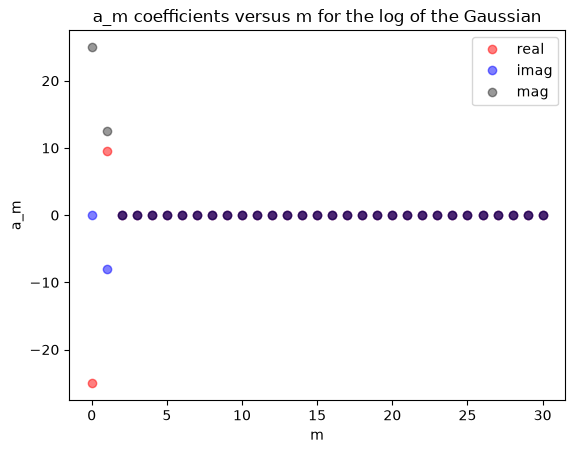

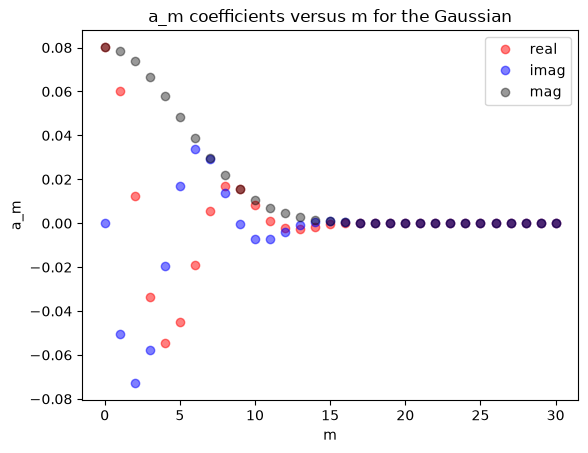

In [7]:
plt.plot(real_coeffs, 'o', color = 'red', alpha=0.5, label='real')
plt.plot(imag_coeffs, 'o', color = 'blue', alpha=0.5, label='imag')
plt.plot(mag_coeffs, 'o', color = 'black', alpha=0.4, label='mag')
plt.ylabel('a_m')
plt.xlabel('m')
plt.title("a_m coefficients versus m for the log of the Gaussian")
plt.legend()
plt.show()

plt.plot(real_g_coeffs, 'o', color = 'red', alpha=0.5, label='real')
plt.plot(imag_g_coeffs, 'o', color = 'blue', alpha=0.5, label='imag') # no imaginary component
plt.plot(mag_g_coeffs, 'o', color = 'black', alpha=0.4, label='mag')
plt.ylabel('a_m')
plt.xlabel('m')
plt.title("a_m coefficients versus m for the Gaussian")
plt.legend()
# plt.semilogy()
plt.show()

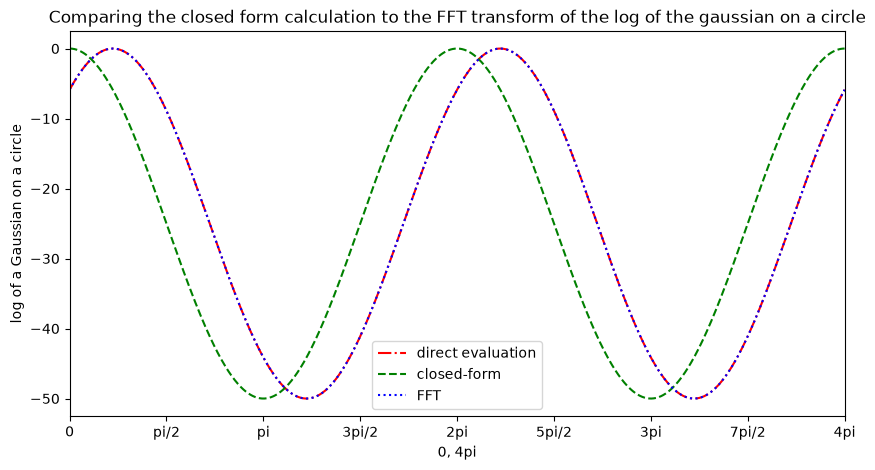

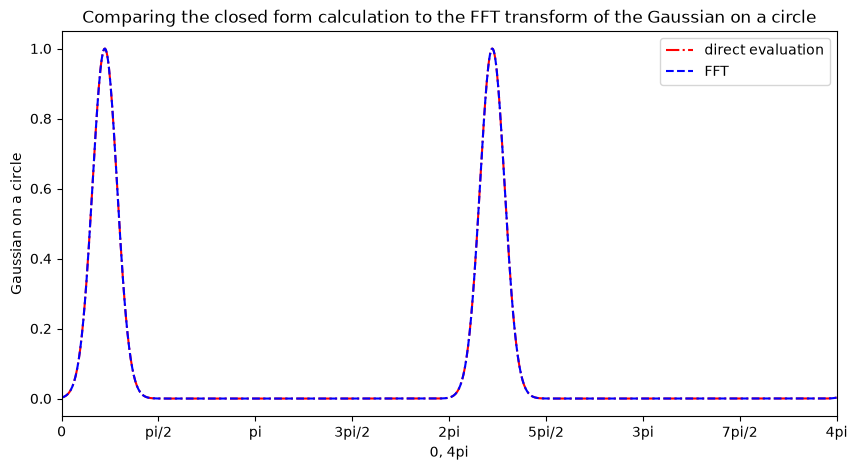

In [8]:
x = np.linspace(0, 4 * np.pi, 1000)
ticks = np.linspace(0, 4*np.pi, 9)
labels = ['0', 'pi/2', 'pi', '3pi/2', '2pi', '5pi/2', '3pi', '7pi/2', '4pi']

y1 = log_gaussian_on_circle(x, phi_mu, sigma)
z_unnorm = log_coeffs(sigma, R=R, A=1.0, phi_mu=phi_mu)
y5 = eval_log(x, z_unnorm)                                       
y2 = eval_fft_series(log_coeffs1, x)                             


plt.figure(figsize=(10, 5))
plt.plot(x, y1, color='red', linestyle='-.', label='direct evaluation')
plt.plot(x, y5, color='green', linestyle='--', label='closed-form')
plt.plot(x, y2, color='blue', linestyle=':', label='FFT')
plt.xlim(0, 4*np.pi)
plt.xlabel("0, 4pi")
plt.ylabel("log of a Gaussian on a circle")
plt.title("Comparing the closed form calculation to the FFT transform of the log of the gaussian on a circle") 
plt.legend()
plt.xticks(ticks, labels)
plt.show()

y3 = gaussian_on_circle(x, phi_mu, sigma)                         
y4 = eval_fft_series(gaussian_coeffs, x) 

plt.figure(figsize=(10, 5))
plt.plot(x, y3, color='red', linestyle='-.', label='direct evaluation')
plt.plot(x, y4, color='blue', linestyle='--', label='FFT')
plt.xlim(0, 4*np.pi)
plt.xticks(ticks, labels)
plt.xlabel("0, 4pi")
plt.ylabel("Gaussian on a circle")
plt.title("Comparing the closed form calculation to the FFT transform of the Gaussian on a circle") 
plt.legend()
plt.show()

Integrating the Gaussian over the circle which is the average of N samples times 2pi which is 2pi * a0.

In [10]:
N = 256
phi = 2 * np.pi * np.arange(N) / N
f = np.exp(eval_log(phi, z))

coeffs = np.fft.fft(f) / N
a0 = coeffs[0].real

print(2 * np.pi * a0)
print(2 * np.pi * f.mean())

2.004919338685916
2.0049193386859154


Notice that the shape of our graph is parabolic. It shows us how rapidly the magnitude of the Fourier coefficients shrink with shows us how many terms we would need for precision. It also shows that the width of our gaussian(covariance/sigma) determines how many terms we need on the circle. When sigma is small, the Gaussian is spiked, and we require higher frequencies to avoid missing the spike along the circle. 

Answering the question of evaluating a likelihood in orbit fitting. How many evaluations does an accurate integral requre, when does a spiked Gaussian get missed. 